# Finding suspicious refunds, voids and discounts in retail payment data

**Question:** a retail chain has hundreds of thousands of transactions a year. Loss-prevention teams cannot check them all.
*Which cases should they review first, so that the money recovered is larger than the cost of reviewing?*

**Approach**
1. Explore the payment data (payment-method mix, timing)
2. Keep only *exception* transactions: refunds, voids and discounts (features built in pandas **and in SQL**)
3. Baseline: simple business rules
4. Machine learning: **Isolation Forest** (unsupervised: no fraud labels needed)
5. **Cost-sensitive evaluation**: net savings = fraud value recovered − cost of reviews
6. A cashier-level review queue

> **Data:** fully **synthetic**, generated by `generate_data.py` (8 stores, 1 year, ~360,000 transactions, amounts in SEK).
> Real point-of-sale data is confidential. Fraud labels exist only so we can measure how well each method works.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import detection as dt
import generate_data

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
IMG = Path("images"); IMG.mkdir(exist_ok=True)

# Create the dataset the first time (takes about a minute), then reuse it
if not generate_data.OUT_FILE.exists():
    generate_data.OUT_FILE.parent.mkdir(exist_ok=True)
    generate_data.generate().to_csv(generate_data.OUT_FILE, index=False)

df = pd.read_csv(generate_data.OUT_FILE, parse_dates=["timestamp"])
print(f"{len(df):,} transactions, {df.store_id.nunique()} stores, {df.cashier_id.nunique()} cashiers")
df.head()

358,365 transactions, 8 stores, 56 cashiers


,txn_id,timestamp,store_id,cashier_id,txn_type,payment_method,amount_sek,discount_pct,has_receipt,minutes_since_sale,is_fraud,fraud_type
0,T0000000,2025-10-01 09:00:00,S05,C05G,sale,card,52.50,0.00,NaN,NaN,0,NaN
1,T0000001,2025-10-01 09:00:00,S07,C07F,sale,cash,648.68,0.00,NaN,NaN,0,NaN
2,T0000002,2025-10-01 09:00:00,S07,C07A,sale,gift_card,211.05,0.00,NaN,NaN,0,NaN
3,T0000003,2025-10-01 09:00:00,S04,C04C,sale,card,91.54,0.00,NaN,NaN,0,NaN
4,T0000004,2025-10-01 09:00:00,S01,C01C,sale,cash,269.68,0.00,NaN,NaN,0,NaN


## 1. Explore the payment data
### Payment-method mix over time
The simulation lets Swish grow and cash shrink during the year, as in Swedish payment statistics.

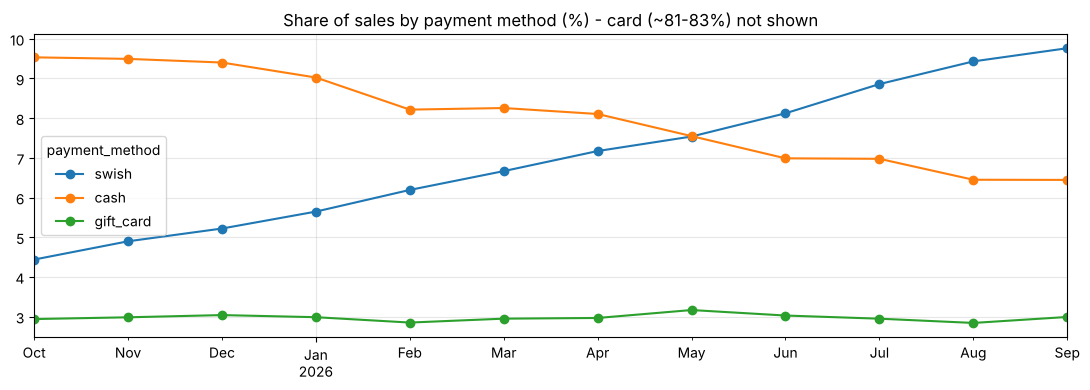

payment_method,card,cash,gift_card,swish
timestamp,,,,
2025-10,83.10,9.50,2.90,4.40
2025-11,82.60,9.50,3.00,4.90
2025-12,82.30,9.40,3.00,5.20


In [2]:
sales = df[df.txn_type == "sale"]
mix = (sales.groupby([sales.timestamp.dt.to_period("M"), "payment_method"]).size()
            .unstack().pipe(lambda t: t.div(t.sum(axis=1), axis=0) * 100))

fig, ax = plt.subplots(figsize=(11, 4))
mix[["swish", "cash", "gift_card"]].plot(ax=ax, marker="o")
ax.set_title("Share of sales by payment method (%) - card (~81-83%) not shown")
ax.set_xlabel(""); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(IMG / "payment_mix.png", dpi=120); plt.show()
mix.round(1).head(3)

### When do exceptions happen?

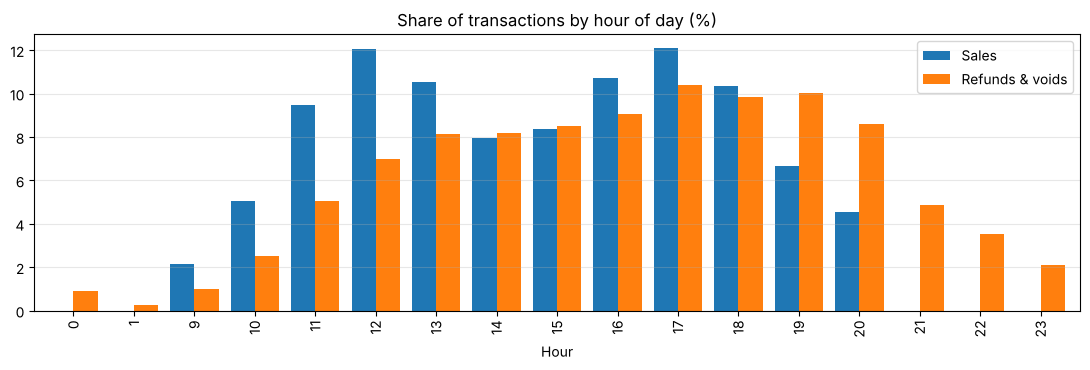

In [3]:
exc_all = df[df.txn_type != "sale"]
by_hour = pd.DataFrame({
    "Sales": sales.timestamp.dt.hour.value_counts(normalize=True),
    "Refunds & voids": exc_all.timestamp.dt.hour.value_counts(normalize=True),
}).sort_index() * 100

ax = by_hour.plot.bar(figsize=(11, 3.8), width=0.8)
ax.set_title("Share of transactions by hour of day (%)"); ax.set_xlabel("Hour"); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(IMG / "hourly_pattern.png", dpi=120); plt.show()

Refunds and voids are relatively more common in the last hours before closing: a first hint of where to look.

## 2. Exception transactions and features
Fraud hides in refunds, voids and discounts, so we only score those.

In [4]:
exc = dt.add_features(dt.exceptions(df), df)
print(f"{len(exc):,} exception transactions ({len(exc)/len(df):.1%} of all)")
print(f"Known fraud cases among them: {exc.is_fraud.sum():,} ({exc.is_fraud.mean():.1%})")
exc[dt.FEATURES].describe().T[["mean", "min", "max"]]

18,754 exception transactions (5.2% of all)
Known fraud cases among them: 1,097 (5.8%)


,mean,min,max
log_amount,4.68,1.17,8.12
hour,16.14,0.00,23.98
late_hour,0.23,0.00,1.00
is_cash,0.11,0.00,1.00
no_receipt,0.06,0.00,1.00
discount_pct,0.10,0.00,1.00
round_amount,0.01,0.00,1.00
is_refund,0.39,0.00,1.00
is_void,0.24,0.00,1.00
minutes_since_sale,0.51,0.00,14.00


**Features used**
- *Transaction*: value at risk (log), hour, late hour, cash, refund without receipt, discount %, round amount, refund/void flags, minutes between sale and void
- *Cashier*: exception rate and late-hour share, compared with colleagues **in the same store** (z-score)

### The same features in SQL
In a company the data usually sits in a database, so the features are also written in **SQL** (`sql/exception_features.sql`).
It uses common table expressions (`WITH`), `CASE WHEN`, joins and **window functions** (`OVER (PARTITION BY store_id)`) for the within-store z-scores.
[DuckDB](https://duckdb.org) runs the SQL directly on the pandas table, with no database server needed.

In [5]:
import duckdb

con = duckdb.connect()
con.register("transactions", df)                      # make the DataFrame queryable as a table
sql_features = con.sql(open("sql/exception_features.sql").read()).df()

# Check: SQL and pandas give the same numbers
pandas_features = exc.sort_values("txn_id").reset_index(drop=True)
max_diff = max(abs(sql_features[c].astype(float) - pandas_features[c].astype(float)).max()
               for c in dt.FEATURES)
print(f"{len(sql_features):,} rows from SQL vs {len(pandas_features):,} from pandas; "
      f"largest difference in any feature: {max_diff:.1e}")

18,754 rows from SQL vs 18,754 from pandas; largest difference in any feature: 6.9e-15


Three typical business questions in SQL (`sql/business_questions.sql`):

In [6]:
queries = open("sql/business_questions.sql").read().split("\n-- name: ")[1:]
results = {q.splitlines()[0]: con.sql("\n".join(q.splitlines()[1:])).df() for q in queries}

print("Refunds without receipt, by store (top 5):")
display(results["refunds_without_receipt_by_store"].head(5))
print("Cashier with the highest exception rate in each store (top 5):")
display(results["top_cashier_per_store"].head(5))

Refunds without receipt, by store (top 5):


,store_id,refunds_no_receipt,value_sek,pct_of_refunds
0,S07,263,"96,893.00",21.80
1,S05,233,"71,846.00",19.80
2,S06,89,"18,213.00",14.20
3,S02,154,"26,408.00",13.60
4,S03,73,"11,873.00",13.20


Cashier with the highest exception rate in each store (top 5):


,store_id,cashier_id,exceptions_per_100_sales,rank_in_store
0,S08,C08E,9.57,1
1,S06,C06B,9.57,1
2,S07,C07G,7.61,1
3,S05,C05D,7.16,1
4,S04,C04E,5.76,1


## 3. Baseline: business rules
Flag a case if: refund without receipt, OR discount ≥ 50%, OR cash void in the last two hours.

In [7]:
REVIEW_COST = 150   # SEK per investigation (assumption: ~30 min of staff time)

rules = dt.rule_flags(exc)
rules_result = dt.evaluate_flags(exc, rules, REVIEW_COST)
rules_result

cases reviewed            2,301.00
fraud found                 679.00
precision                     0.30
recall                        0.62
value recovered (SEK)   289,129.38
review cost (SEK)       345,150.00
net savings (SEK)       -56,020.62
dtype: float64

The rules find many fraud cases, but they also flag thousands of honest refunds and discounts.
**After paying for all those reviews, the rules can lose money.**

## 4. Isolation Forest
An unsupervised model: it learns what *normal* exceptions look like and gives unusual ones a high score.
The team then reviews cases from the highest score down.

In [8]:
from sklearn.metrics import roc_auc_score

exc["if_score"] = dt.isolation_forest(exc)
print(f"ROC AUC: {roc_auc_score(exc.is_fraud, exc.if_score):.3f}  (1.0 = perfect ranking, 0.5 = random)")
exc.sort_values("if_score", ascending=False)[
    ["timestamp", "store_id", "cashier_id", "txn_type", "payment_method",
     "amount_sek", "discount_pct", "if_score", "is_fraud"]].head(10)

ROC AUC: 0.941  (1.0 = perfect ranking, 0.5 = random)


,timestamp,store_id,cashier_id,txn_type,payment_method,amount_sek,discount_pct,if_score,is_fraud
300212,2026-08-01 11:10:59.346123285,S07,C07B,refund,cash,"1,000.00",0.00,0.70,1
215981,2026-05-04 11:56:02.359860002,S07,C07B,refund,cash,"1,000.00",0.00,0.70,1
272807,2026-07-03 11:43:56.452527210,S07,C07B,refund,cash,"1,000.00",0.00,0.70,1
336783,2026-09-08 10:47:55.383175800,S05,C05D,refund,cash,500.00,0.00,0.70,1
6521,2025-10-07 19:01:12.009415050,S05,C05D,refund,cash,"1,000.00",0.00,0.70,1
245220,2026-06-04 10:53:11.484738446,S05,C05D,refund,cash,400.00,0.00,0.69,1
243417,2026-06-02 10:04:12.947632640,S07,C07B,refund,cash,400.00,0.00,0.69,1
333564,2026-09-05 10:07:51.216578456,S07,C07B,refund,cash,500.00,0.00,0.69,1
258450,2026-06-18 10:20:48.318084619,S07,C07B,refund,cash,600.00,0.00,0.69,1
152127,2026-02-26 10:59:53.493832722,S07,C07B,refund,cash,500.00,0.00,0.69,1


## 5. Cost-sensitive evaluation
Accuracy is not what matters to the business. What matters is:

**net savings(k) = fraud value recovered in the top-k cases − review cost × k**

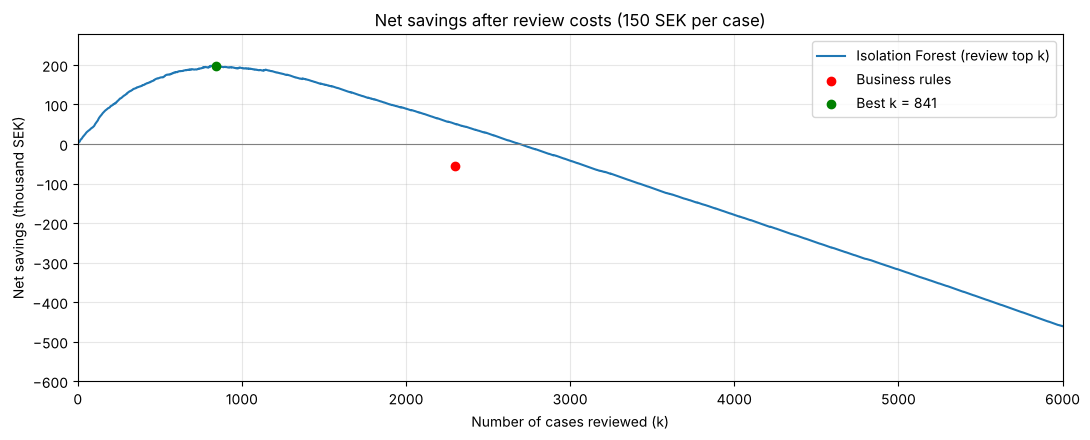

,Business rules,Isolation Forest (best k)
cases reviewed,"2,301.00",841.00
fraud found,679.00,689.00
precision,0.30,0.82
recall,0.62,0.63
value recovered (SEK),"289,129.38","324,090.39"
review cost (SEK),"345,150.00","126,150.00"
net savings (SEK),"-56,020.62","197,940.39"


In [9]:
curve = dt.savings_curve(exc, exc.if_score, REVIEW_COST)
best = curve.loc[curve.net_savings.idxmax()]
k_rules = int(rules_result["cases reviewed"])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(curve.k, curve.net_savings / 1000, label="Isolation Forest (review top k)")
ax.scatter([k_rules], [rules_result["net savings (SEK)"] / 1000], color="red", zorder=3,
           label="Business rules")
ax.scatter([best.k], [best.net_savings / 1000], color="green", zorder=3,
           label=f"Best k = {int(best.k):,}")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlim(0, 6000); ax.set_ylim(-600, best.net_savings / 1000 * 1.4); ax.set_xlabel("Number of cases reviewed (k)")
ax.set_ylabel("Net savings (thousand SEK)")
ax.set_title(f"Net savings after review costs ({REVIEW_COST} SEK per case)")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(IMG / "net_savings.png", dpi=120); plt.show()

summary = pd.DataFrame({
    "Business rules": rules_result,
    "Isolation Forest (best k)": dt.evaluate_flags(
        exc, exc.if_score.rank(ascending=False) <= best.k, REVIEW_COST),
})
summary

### Sensitivity: what if reviews cost more or less?
The best number of reviews depends on the cost of a review, a useful message for managers.

In [10]:
rows = []
for cost in [50, 100, 150, 250, 400]:
    c = dt.savings_curve(exc, exc.if_score, cost)
    b = c.loc[c.net_savings.idxmax()]
    rows.append({"review cost (SEK)": cost, "best k": int(b.k),
                 "fraud found": int(b.fraud_found), "net savings (SEK)": b.net_savings,
                 "rules net savings (SEK)": dt.evaluate_flags(exc, rules, cost)["net savings (SEK)"]})
pd.DataFrame(rows)

,review cost (SEK),best k,fraud found,net savings (SEK),rules net savings (SEK)
0,50,1371,806,"303,122.18","174,079.38"
1,100,1146,774,"245,272.49","59,029.38"
2,150,841,689,"197,940.38","-56,020.62"
3,250,612,565,"122,549.64","-286,120.62"
4,400,336,331,"54,599.69","-631,270.62"


## 6. Cashier review queue
Investigators often start from *people*, not single receipts. We rank cashiers by the
sum of their most unusual exception scores.

In [11]:
top_share = exc.if_score.quantile(0.95)
queue = (exc.assign(top=exc.if_score >= top_share)
            .groupby(["store_id", "cashier_id"])
            .agg(exceptions=("txn_id", "size"), top_5pct_cases=("top", "sum"),
                 value_at_risk_sek=("value_at_risk", "sum"),
                 actually_fraudulent=("is_fraud", "max"))
            .sort_values("top_5pct_cases", ascending=False).reset_index())
queue.head(10)

,store_id,cashier_id,exceptions,top_5pct_cases,value_at_risk_sek,actually_fraudulent
0,S08,C08E,448,217,"113,436.90",1
1,S06,C06B,432,195,"104,956.47",1
2,S07,C07B,543,175,"170,785.42",1
3,S05,C05D,542,138,"142,054.01",1
4,S05,C05E,520,24,"103,087.54",1
5,S07,C07G,568,15,"120,284.57",1
6,S02,C02F,422,14,"77,031.43",0
7,S01,C01F,367,8,"60,869.60",0
8,S02,C02E,427,6,"62,525.81",0
9,S04,C04G,316,6,"56,948.63",0


## 7. Conclusions
- Simple rules catch fraud but flag too many honest cases; once review costs are counted, they can **lose money**.
- Isolation Forest ranks cases so the team can stop at the point where reviewing stops paying off.
- **Cashier-level features** (behaviour compared with colleagues in the same store) carry much of the signal.
- The best review volume depends on the review cost, so the model should be tuned to the business's own costs.

**Limitations:** synthetic data with simplified fraud patterns; real fraud adapts to controls.
On real data I would validate on cases confirmed by audit teams and monitor model drift over time.

**Related research:** Pierce, Snow & McAfee (2015), *Management Science*, on IT monitoring and employee theft;
Correa Bahnsen et al. on cost-sensitive fraud detection; Liu, Ting & Zhou (2008) on Isolation Forest.